# Interpolation to stations: IFS-HRES 2 m temperature

This example illustrates {func}`~grid_process.grid_interp.interp2poi` with two methods:

- `nearest`: value of the nearest grid point;
- `temp`: altitude-aware interpolation designed for temperature. It fits a local sounding on the `k`
  nearest grid points (with a distance penalizing altitude differences by `z_fact`) and evaluates it at
  the station altitude.

The IFS-HRES 2 m temperature forecast (0.1°, about 9 km) is interpolated to two valley stations,
Visp (VIS) and Ilanz (ILZ), and two mountain stations, Jungfraujoch (JUN) and Säntis (SAE), of the
MeteoSwiss automatic weather station network, and compared with their observations.

*Data: ECMWF open data, © ECMWF, CC BY 4.0. MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss.*

In [1]:
import re
import time
import timeit

import pyproj  # noqa: F401  # import before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import earthkit.data as ekd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

import grid_process.grid_interp as gri
import grid_process.timeseries as tms
import grid_process.units_conv as uconv
from grid_process import data_model as dm

STATIONS = ["VIS", "ILZ", "JUN", "SAE"]
METHODS = {
    "nearest": {"method": "nearest"},
    "temp": {"method": "temp", "z_fact": 15, "k": 50, "weight_power": 0.75},
}
STEPS = list(range(0, 145, 3))  # lead times [h]
BBOX = {"latitude": slice(49.0, 44.0), "longitude": slice(4.0, 12.0)}  # Switzerland with a wide margin

## Source data

We take the oldest IFS-HRES run still available on the ECMWF open data portal, so that observations
cover a large part of the forecast. Open data only serves global fields: the download is cropped to
Switzerland with a wide margin right after loading, since `temp` uses a large neighbourhood (`k=50`).
The `temp` method needs the model orography, which is the surface geopotential `z` at step 0.

In [2]:
OD_ROOT = "https://data.ecmwf.int/forecasts"

# the portal sometimes times out: retry with an increasing delay (earthkit already retries the field downloads)
session = requests.Session()
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry))


def index_url(date: str, hour: int, step: int) -> str:
    return f"{OD_ROOT}/{date}/{hour:02d}z/ifs/0p1/oper/{date}{hour:02d}0000-{step}h-oper-fc-sfc.index"


def oldest_run(last_step: int) -> tuple[str, int]:
    """Oldest run whose first and last steps are both still on the portal (old runs are purged gradually)."""
    dates = sorted(set(re.findall(r'href="/forecasts/(\d{8})/"', session.get(f"{OD_ROOT}/", timeout=30).text)))
    for date in dates:
        for hour in (0, 6, 12, 18):
            if all(session.head(index_url(date, hour, step), timeout=30).ok for step in (0, last_step)):
                return date, hour
    raise RuntimeError("No complete run found on the open data portal")


def open_data(**request) -> ekd.FieldList:
    return ekd.from_source(
        "ecmwf-open-data", model="ifs", resol="0p1", stream="oper", type="fc", date=int(date), time=hour, **request
    ).to_fieldlist()


date, hour = oldest_run(STEPS[-1])
RUN = f"{date[:4]}-{date[4:6]}-{date[6:]} {hour:02d} UTC"
print(f"IFS-HRES run: {RUN}")

ds = open_data(param="2t", step=STEPS).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
ds = ds.squeeze(["level", "level_type"], drop=True).sel(BBOX).astype("float32").load()
ds = uconv.ds_to(ds, {"2t": "degC"})

z_surf = open_data(param="z", levtype="sfc", step=0).to_xarray()["z"].squeeze().reset_coords(drop=True).sel(BBOX)
ds = ds.assign_coords(surface_altitude=(z_surf / 9.80665).astype("float32").assign_attrs(units="m"))
ds = tms.setindex_validtime(ds)  # forecast_reference_time and step -> time
ds

To ensure the stability of our systems and to preserve resources for our operational activities (network, compute, etc.), access to the open-data portal is limited to 500 simultaneous connections. This limit helps us guarantee reliable service for our operational users, especially during periods of high demand. For added reliability, the open-data is replicated across AWS, Azure, and Google Cloud. If you experience difficulties accessing the portal directly, you can also retrieve the data from these cloud platforms.


IFS-HRES run: 2026-10-25 00 UTC


<xarray.Dataset> Size: 818kB
Dimensions:                  (time: 49, latitude: 51, longitude: 80)
Coordinates:
  * time                     (time) datetime64[us] 392B 2026-10-25 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 392B 2026-10-25 ... 2026-1...
  * latitude                 (latitude) float64 408B 49.0 48.9 ... 44.1 44.0
  * longitude                (longitude) float64 640B 4.1 4.2 4.3 ... 11.9 12.0
    surface_altitude         (latitude, longitude) float32 16kB 120.2 ... 394.9
Data variables:
    2t                       (time, latitude, longitude) float32 800kB 11.95 ...
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Stations and observations

The station metadata provide the coordinates and the altitude (`height_masl`) used by `temp`. The
`name` column becomes the `poi` coordinate of the output. Observations are the 10-minute instantaneous
2 m temperature (`tre200s0`).

In [3]:
SMN_URL = "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn"

meta = pd.read_csv(f"{SMN_URL}/ogd-smn_meta_stations.csv", sep=";", encoding="cp1252")
meta = meta.rename(columns={"station_abbr": "name", "station_height_masl": "height_masl"})
pois = gpd.GeoDataFrame(
    meta[["name", "station_name", "height_masl"]],
    geometry=gpd.points_from_xy(meta["station_coordinates_lv95_east"], meta["station_coordinates_lv95_north"]),
    crs="EPSG:2056",
)
pois = pois.set_index("name", drop=False).loc[STATIONS]


def read_smn(abbr: str, granularity: str, periods: tuple[str, ...] = ("recent", "now")) -> pd.DataFrame:
    """Read station data files (granularity 't': 10 min, 'h': hourly); timestamps are in UTC."""
    frames = [
        pd.read_csv(
            f"{SMN_URL}/{abbr.lower()}/ogd-smn_{abbr.lower()}_{granularity}_{period}.csv", sep=";", encoding="cp1252"
        )
        for period in periods
    ]
    df = pd.concat(frames)
    df["time"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    return df.drop_duplicates("time").set_index("time").sort_index()


t_start, t_end = ds.time.values[[0, -1]]
obs = pd.DataFrame({abbr: read_smn(abbr, "t")["tre200s0"] for abbr in STATIONS}).loc[t_start:t_end]
pois[["station_name", "height_masl"]]

,station_name,height_masl
name,,
VIS,Visp,639.0
ILZ,Ilanz,698.0
JUN,Jungfraujoch,3571.0
SAE,Säntis,2501.0


## Interpolation

Each method is called once on all lead times. The duration of this first call is kept for the
benchmark below. On a regular grid with 1D coordinates, `nearest` and `linear` use xarray's interpolation by default (`try_reg=True`), which is efficient for large grids but may be slower for small grids with many other dimensions. They are also run through the generic path (`try_reg=False`) for comparison.

In [4]:
def with_try_reg(methods: dict, data) -> dict:
    """On a grid with 1D spatial coordinates, 'nearest' and 'linear' use xarray's interpolation by default
    (try_reg=True): add the generic path (try_reg=False) to compare both."""
    regular = len(dm.get_spatial_dims(data)) == 2
    runs = {}
    for label, kwargs in methods.items():
        if regular and kwargs["method"] in ("nearest", "linear"):
            runs[label] = kwargs | {"try_reg": True}
            runs[f"{label} (try_reg=False)"] = kwargs | {"try_reg": False}
        else:
            runs[label] = kwargs
    return runs


runs = with_try_reg(METHODS, ds)
results, first_call = {}, {}
for label, kwargs in runs.items():
    t0 = time.perf_counter()
    results[label] = gri.interp2poi(ds, pois, **kwargs)
    first_call[label] = time.perf_counter() - t0
for label in METHODS:
    if f"{label} (try_reg=False)" in results:
        diff = abs(results[label]["2t"] - results[f"{label} (try_reg=False)"]["2t"])
        print(
            f"{label}, try_reg=True vs. False: mean abs. difference {diff.mean().item():.3g} °C, max. {diff.max().item():.3g} °C"
        )

# model altitude at the nearest grid point, to compare with the station altitude
model_alt = gri.interp2poi(ds["surface_altitude"].reset_coords(drop=True).to_dataset(name="alt"), pois, "nearest")
results["temp"]

nearest, try_reg=True vs. False: mean abs. difference 0 °C, max. 0 °C


<xarray.Dataset> Size: 2kB
Dimensions:                  (poi: 4, time: 49)
Coordinates:
  * poi                      (poi) <U3 48B 'VIS' 'ILZ' 'JUN' 'SAE'
  * time                     (time) datetime64[us] 392B 2026-10-25 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 392B 2026-10-25 ... 2026-1...
Data variables:
    2t                       (poi, time) float32 784B 4.073 3.93 ... -5.332
Attributes:
    institution:  ECMWF

## Visual comparison

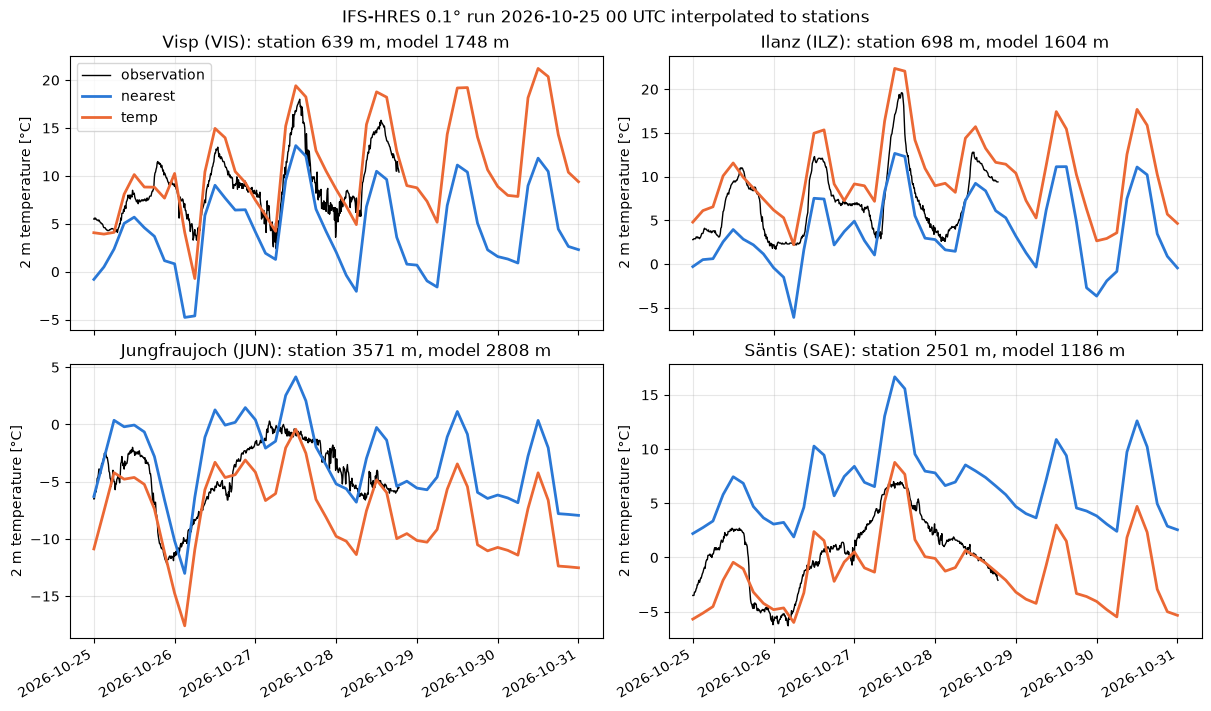

In [5]:
COLORS = {"nearest": "#2a78d6", "temp": "#eb6834"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for ax, abbr in zip(axes.flat, STATIONS):
    ax.plot(obs.index, obs[abbr], color="black", lw=1, label="observation")
    for label in METHODS:
        res = results[label]
        ax.plot(res.time, res["2t"].sel(poi=abbr), color=COLORS[label], lw=2, label=label)
    station = pois.loc[abbr]
    ax.set_title(
        f"{station.station_name} ({abbr}): station {station.height_masl:.0f} m, "
        f"model {model_alt['alt'].sel(poi=abbr).item():.0f} m"
    )
    ax.set_ylabel("2 m temperature [°C]")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"IFS-HRES 0.1° run {RUN} interpolated to stations")
fig.autofmt_xdate()
plt.show()

## Performance benchmark

The first call includes building the neighbour search structures, which `grid_process` caches.
Subsequent calls on the same grid and stations (e.g. for other variables or runs) reuse them: their
runtime is the mean ± standard deviation over 5 repetitions.

In [6]:
def benchmark(func, data, target, methods: dict, first_call: dict, repeat: int = 5) -> pd.DataFrame:
    rows = []
    for label, kwargs in methods.items():
        warm = np.array(timeit.repeat(lambda: func(data, target, **kwargs), number=1, repeat=repeat))
        rows.append(
            {
                "method": label,
                "kwargs": ", ".join(f"{k}={v}" for k, v in kwargs.items() if k != "method"),
                "first call [s]": first_call[label],
                "subsequent calls [s]": f"{warm.mean():.3f} ± {warm.std():.3f}",
            }
        )
    return pd.DataFrame(rows).set_index("method").round(3)


print(f"{ds.latitude.size * ds.longitude.size} grid points × {ds.time.size} lead times -> {len(pois)} stations")
benchmark(gri.interp2poi, ds, pois, runs, first_call)

4080 grid points × 49 lead times -> 4 stations


,kwargs,first call [s],subsequent calls [s]
method,,,
nearest,try_reg=True,0.016,0.005 ± 0.001
nearest (try_reg=False),try_reg=False,0.009,0.007 ± 0.001
temp,"z_fact=15, k=50, weight_power=0.75",0.015,0.007 ± 0.000


## Takeaways

- In complex terrain the nearest grid point of a 9 km model can be more than 1000 m above (valleys) or
  below (summits) the station. `nearest` then inherits a large altitude-related bias, too cold in
  valleys and too warm on mountains.
- `temp` removes most of this bias by evaluating the local vertical temperature profile of the model at
  the station altitude. Effects the model does not resolve, such as shallow night-time inversions in
  valleys, remain.
- Both methods are fast for a few stations. `temp` fits one sounding per station and becomes the more
  expensive method for thousands of points.
- On the regular IFS grid, `nearest` gives the same values with the default regular path
  (`try_reg=True`, xarray's interpolation) and with the generic path (`try_reg=False`).